# Automated Authentication of Van Gogh Paintings
### Through Image Processing and Feature Engineering (ARTI 403, Group 3)


---
# PART 1: PRE-PROCESSING
## 0. Setup

In [1]:
import os, json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from joblib import Parallel, delayed, dump
from skimage.feature import local_binary_pattern, graycomatrix, graycoprops
from skimage.measure import shannon_entropy

from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             f1_score, confusion_matrix, classification_report)
from sklearn.model_selection import (train_test_split, StratifiedGroupKFold,
                                     GridSearchCV, cross_val_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

warnings.filterwarnings("ignore")
Image.MAX_IMAGE_PIXELS = None         
sns.set_theme(style="whitegrid")
SEED = 42

### Configuration
**Label scheme:** `0 = authentic`, `1 = counterfeit / non-authentic`. 

In [2]:
DATA_ROOT = Path(".")               
WORK_DIR  = Path("work")
STD_DIR   = WORK_DIR / "standardized"  
FEAT_DIR  = WORK_DIR / "features"      
for d in (STD_DIR, FEAT_DIR):
    d.mkdir(parents=True, exist_ok=True)

LABEL_NAMES = {0: "authentic", 1: "counterfeit/non-van Gogh"}
# Folder-based sources: every image in the folder gets the same label.
SOURCES = [
    dict(folder="Vincent Forgeries Wacker", source="VG-Auth", subtype="wacker_forgery",      label=1),
    dict(folder="Vincent Stable Diffusion", source="VG-Auth", subtype="stable_diffusion",    label=1),
    dict(folder="Vincent GAN finetune",     source="VG-Auth", subtype="stylegan3_finetuned", label=1),
    dict(folder="Vincent GAN random",       source="VG-Auth", subtype="stylegan3_random",    label=1),
]

VGDB = dict(folder="vgdb_2016",
            csv="vgdb_2016.csv",
            sets=("train", "test", "check"),   # subfolders to read
            id_col="id",                        # CSV column that matches the image file name (without extension)
            label_col="label",                  # CSV column that says whether it is a van Gogh
            vangogh_value="vangogh",            # the value in label_col that means "van Gogh"
            label_vangogh=0,                    # label given to van Gogh paintings (authentic)
            label_other=1)                      # label for other artists (None = exclude them)
IMG_EXT = {".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp"}


MAIN_CFG = "enhanced"        # the variant used for the main classifiers

TEST_SIZE = 0.2
N_JOBS    = 2                # raise if you have the RAM/cores (large PNGs need ~1.5 GB each while loading)
FORCE_RECOMPUTE = False      # True = ignore cached standardised images / feature tables

## 1. Data loading and labelling
Builds one metadata table (one row per painting). It records the source, sub-type, label, and the image size and format. Size and format matter because the two datasets differ a lot (23k px PNGs vs 512 px StyleGAN images), which can leak the label through resolution alone.

In [3]:
def _fake_painting(r, w, h, authentic):
    canvas = np.full((h, w, 3), r.integers(80, 170, 3), np.uint8)
    for _ in range(1500):
        x, y = int(r.integers(0, w)), int(r.integers(0, h))
        ang = np.pi / 4 + r.normal(0, 0.3) if authentic else r.uniform(0, np.pi)
        length = int(r.integers(15, 40)) if authentic else int(r.integers(5, 15))
        col = tuple(int(c) for c in np.clip(canvas[y, x].astype(int) + r.integers(-60, 60, 3), 0, 255))
        cv2.line(canvas, (x, y), (int(x + length * np.cos(ang)), int(y + length * np.sin(ang))),
                 col, 3 if authentic else 2)
    return canvas

In [4]:
def image_row(p, source, subtype, label, **extra):
    with Image.open(p) as im:                      # reads the header only, not the pixels
        w, h = im.size
    return dict(path=str(p), source=source, subtype=subtype, label=label, width=w, height=h,
                fmt=p.suffix.lower().lstrip("."), **extra)

def list_images(folder):
    return [p for p in sorted(Path(folder).rglob("*")) if p.suffix.lower() in IMG_EXT]

def build_metadata(sources, root, vgdb=VGDB):
    rows = []

    # 1) Forgeries / AI-generated images: every image in the folder gets the folder's label
    for s in sources:
        if s["label"] is None:
            continue
        folder = Path(root) / s["folder"]
        if not folder.exists():
            print(f"[warn] folder not found, skipping: {folder}")
            continue
        rows += [image_row(p, s["source"], s["subtype"], s["label"]) for p in list_images(folder)]

    # 2) VGDB-2016: the label comes from the folder name (vg = van Gogh, nvg = other artist)
    vroot = Path(root) / vgdb["folder"]
    classes = {"vg": ("van_gogh", vgdb["label_vangogh"]),
               "nvg": ("other_artist", vgdb["label_other"])}
    for subset in ("train", "test"):
        for cls, (subtype, label) in classes.items():
            folder = vroot / subset / cls
            if label is None:                      # label_other=None excludes the other artists
                continue
            if not folder.exists():
                print(f"[warn] folder not found, skipping: {folder}")
                continue
            rows += [image_row(p, "VGDB-2016", subtype, label, vgdb_set=subset) for p in list_images(folder)]
    n_check = len(list_images(vroot / "check")) if (vroot / "check").exists() else 0
    print(f"VGDB check/ folder: {n_check} unlabelled images skipped")

    if not rows:
        raise FileNotFoundError("No images found. Check DATA_ROOT / SOURCES / VGDB.")
    df = pd.DataFrame(rows)
    df.insert(0, "painting_id", [f"P{i:04d}" for i in range(len(df))])
    return df

meta = build_metadata(SOURCES, DATA_ROOT)
print(f"{len(meta)} paintings loaded")
print("\nlabel counts (BOTH 0 and 1 must appear):")
print(meta["label"].value_counts())
display(pd.crosstab(meta["subtype"], meta["label"]))
meta.head()

VGDB check/ folder: 2 unlabelled images skipped
430 paintings loaded

label counts (BOTH 0 and 1 must appear):
label
1    306
0    124
Name: count, dtype: int64


label,0,1
subtype,,
other_artist,0,207
stable_diffusion,0,30
stylegan3_finetuned,0,30
stylegan3_random,0,30
van_gogh,124,0
wacker_forgery,0,9


,painting_id,path,source,subtype,label,width,height,fmt,vgdb_set
0,P0000,Vincent Forgeries Wacker\108801.jpg,VG-Auth,wacker_forgery,1,776,600,jpg,NaN
1,P0001,Vincent Forgeries Wacker\1231.jpg,VG-Auth,wacker_forgery,1,2352,2864,jpg,NaN
2,P0002,Vincent Forgeries Wacker\1969141.jpg,VG-Auth,wacker_forgery,1,2400,2912,jpg,NaN
3,P0003,Vincent Forgeries Wacker\230942.jpg,VG-Auth,wacker_forgery,1,733,958,jpg,NaN
4,P0004,Vincent Forgeries Wacker\46628.jpg,VG-Auth,wacker_forgery,1,3194,4000,jpg,NaN


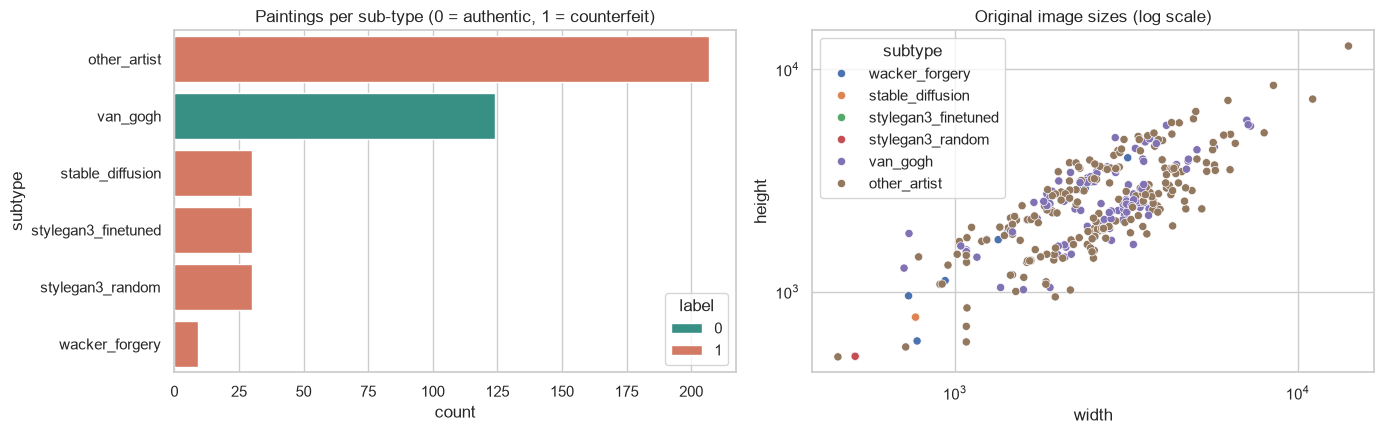

Sub-type x file-format table (a strong imbalance here is a potential shortcut for the classifier):


fmt,jpg,png
subtype,,
other_artist,0,207
stable_diffusion,30,0
stylegan3_finetuned,0,30
stylegan3_random,0,30
van_gogh,0,124
wacker_forgery,9,0


Median size per sub-type:


,width,height
subtype,,
other_artist,2709.0,2463.0
stable_diffusion,768.0,768.0
stylegan3_finetuned,512.0,512.0
stylegan3_random,512.0,512.0
van_gogh,2703.5,2551.0
wacker_forgery,1424.0,1847.0


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

order = meta.groupby("subtype").size().sort_values(ascending=False).index
sns.countplot(data=meta, y="subtype", hue="label", order=order, ax=axes[0], dodge=False,
              palette={0: "#2a9d8f", 1: "#e76f51"})
axes[0].set_title("Paintings per sub-type (0 = authentic, 1 = counterfeit)")

sns.scatterplot(data=meta, x="width", y="height", hue="subtype", ax=axes[1], s=35)
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_title("Original image sizes (log scale)")
plt.tight_layout(); plt.show()

print("Sub-type x file-format table (a strong imbalance here is a potential shortcut for the classifier):")
display(pd.crosstab(meta["subtype"], meta["fmt"]))
print("Median size per sub-type:")
display(meta.groupby("subtype")[["width", "height"]].median())

## 2. Train / test split (at painting level)
The split is made **before** any patches are extracted, so patches from one painting can never appear in both train and test (data leakage, see reference [4]). Stratifying by sub-type keeps the rare classes, such as the 9 Wacker forgeries, in both sets.

In [6]:
strat = meta["subtype"] if meta["subtype"].value_counts().min() >= 2 else meta["label"]
train_ids, test_ids = train_test_split(meta["painting_id"], test_size=TEST_SIZE,
                                       stratify=strat, random_state=SEED)
meta["split"] = np.where(meta["painting_id"].isin(set(train_ids)), "train", "test")

assert set(train_ids).isdisjoint(set(test_ids))
print(pd.crosstab(meta["subtype"], meta["split"], margins=True))
meta.to_csv(WORK_DIR / "metadata.csv", index=False)

split                test  train  All
subtype                              
other_artist           41    166  207
stable_diffusion        6     24   30
stylegan3_finetuned     6     24   30
stylegan3_random        6     24   30
van_gogh               25     99  124
wacker_forgery          2      7    9
All                    86    344  430


## 3. Image pre-processing and enhancement 

<img src="Diagrams/preprocessing_pipeline.png" width="1000">

In [7]:
# Create folders for processed images
RESIZED_DIR = WORK_DIR / "resized"
ENHANCED_DIR = WORK_DIR / "enhanced"

RESIZED_DIR.mkdir(parents=True, exist_ok=True)
ENHANCED_DIR.mkdir(parents=True, exist_ok=True)

In [8]:
def preprocess_image(path):
    img = cv2.imread(str(path))

    if img is None:
        raise ValueError(f"Cannot read: {path}")

    img = cv2.resize(img, (256, 256), interpolation=cv2.INTER_AREA)

    img = cv2.GaussianBlur(img, (3, 3), 0)

    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    l = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(l)

    enhanced = cv2.merge((l, a, b))
    enhanced = cv2.cvtColor(enhanced, cv2.COLOR_LAB2BGR)

    return img, enhanced

In [9]:
# Process all images in the dataset
processed_rows = []

for _, row in meta.iterrows():
    try:
        resized, enhanced = preprocess_image(row["path"])
        image_id = str(row["painting_id"])

        # Save both image versions
        resized_path = RESIZED_DIR / f"{image_id}.png"
        enhanced_path = ENHANCED_DIR / f"{image_id}.png"

        cv2.imwrite(str(resized_path), resized)
        cv2.imwrite(str(enhanced_path), enhanced)

        processed_rows.append({
            "painting_id": image_id,
            "resized_path": str(resized_path),
            "enhanced_path": str(enhanced_path)
        })

    except Exception as e:
        print("Skipped:", row["path"], e)

# Add processed paths to metadata
processed_df = pd.DataFrame(processed_rows)
meta = meta.drop(
    columns=["resized_path", "enhanced_path"],
    errors="ignore"
).merge(processed_df, on="painting_id", how="left")

print("Processed images:", len(processed_df))
display(processed_df.head())

Processed images: 430


,painting_id,resized_path,enhanced_path
0,P0000,work\resized\P0000.png,work\enhanced\P0000.png
1,P0001,work\resized\P0001.png,work\enhanced\P0001.png
2,P0002,work\resized\P0002.png,work\enhanced\P0002.png
3,P0003,work\resized\P0003.png,work\enhanced\P0003.png
4,P0004,work\resized\P0004.png,work\enhanced\P0004.png


All paintings are resized to a standard size, smoothed to reduce noise, and enhanced using histogram equalization on the LAB lightness channel. This prepares the images for further processing and feature extraction.

## 4. Segmentation into patches / regions

<img src="Diagrams/segmentation_pipeline.png" width="1000">

In [10]:
# Create a folder for image patches
PATCH_DIR = WORK_DIR / "patches"
PATCH_DIR.mkdir(parents=True, exist_ok=True)

In [11]:
patch_rows = []

# Process every enhanced image
for _, row in meta.dropna(subset=["enhanced_path"]).iterrows():

    img = cv2.imread(str(row["enhanced_path"]))
    painting_id = str(row["painting_id"])

    # Divide each image into 64x64 patches
    for y in range(0, 256, 64):
        for x in range(0, 256, 64):

            patch = img[y:y+64, x:x+64]

            # Save each patch
            patch_path = PATCH_DIR / f"{painting_id}_{y}_{x}.png"
            cv2.imwrite(str(patch_path), patch)

            patch_rows.append({
                "painting_id": painting_id,
                "patch_path": str(patch_path),
                "x": x,
                "y": y
            })

# Create patch metadata
patches_df = pd.DataFrame(patch_rows)

print("Total patches:", len(patches_df))
display(patches_df.head())

Total patches: 6880


,painting_id,patch_path,x,y
0,P0000,work\patches\P0000_0_0.png,0,0
1,P0000,work\patches\P0000_0_64.png,64,0
2,P0000,work\patches\P0000_0_128.png,128,0
3,P0000,work\patches\P0000_0_192.png,192,0
4,P0000,work\patches\P0000_64_0.png,0,64


Each enhanced painting is divided into 16 non-overlapping patches of size 64 × 64 pixels. This helps analyze local details such as texture and brushstroke patterns in different regions of the painting.

## 5. Edge detection and morphological processing

<img src="Diagrams/edgedetection_pipeline.png" width="1000">

In [12]:
# Create folders for edge results
EDGE_DIR = WORK_DIR / "edges"
MORPH_DIR = WORK_DIR / "morphology"

EDGE_DIR.mkdir(parents=True, exist_ok=True)
MORPH_DIR.mkdir(parents=True, exist_ok=True)

In [13]:
edge_rows = []

# Create a kernel for morphology
kernel = np.ones((3, 3), np.uint8)

for _, row in meta.dropna(subset=["enhanced_path"]).iterrows():

    img = cv2.imread(str(row["enhanced_path"]))
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Detect image edges
    edges = cv2.Canny(gray, 100, 200)

    # Apply dilation and erosion
    dilated = cv2.dilate(edges, kernel, iterations=1)
    eroded = cv2.erode(dilated, kernel, iterations=1)

    # Save the results
    image_id = str(row["painting_id"])

    edge_path = EDGE_DIR / f"{image_id}.png"
    morph_path = MORPH_DIR / f"{image_id}.png"

    cv2.imwrite(str(edge_path), edges)
    cv2.imwrite(str(morph_path), eroded)

    # Calculate edge features
    edge_rows.append({
        "painting_id": image_id,
        "edge_path": str(edge_path),
        "morph_path": str(morph_path),
        "edge_density": np.mean(edges > 0),
        "morph_density": np.mean(eroded > 0)
    })

edges_df = pd.DataFrame(edge_rows)

print("Images analyzed:", len(edges_df))
display(edges_df.head())

Images analyzed: 430


,painting_id,edge_path,morph_path,edge_density,morph_density
0,P0000,work\edges\P0000.png,work\morphology\P0000.png,0.277039,0.554764
1,P0001,work\edges\P0001.png,work\morphology\P0001.png,0.177948,0.330948
2,P0002,work\edges\P0002.png,work\morphology\P0002.png,0.241928,0.490646
3,P0003,work\edges\P0003.png,work\morphology\P0003.png,0.269318,0.530609
4,P0004,work\edges\P0004.png,work\morphology\P0004.png,0.202545,0.398666


Canny edge detection is applied to identify painting edges, followed by dilation and erosion to refine them.

**Edge density** and **morphological density** are extracted to help the model learn differences in texture, brushstrokes, and structural patterns between authentic and forged paintings.

## 6. Colour processing and feature extraction

<img src="Diagrams/featureextraction_pipeline.png" width="1000">

In [14]:
def color_intensity_features(img):
    f = {}
    b, g, r = [img[:, :, i].astype(np.float32) for i in range(3)]
    for name, ch in (("B", b), ("G", g), ("R", r)):
        f[f"{name}_mean"] = ch.mean()
        f[f"{name}_std"] = ch.std()

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    f["intensity_mean"] = gray.mean()
    f["intensity_std"] = gray.std()
    f["intensity_p05"], f["intensity_p50"], f["intensity_p95"] = np.percentile(gray, [5, 50, 95])
    f["entropy"] = shannon_entropy(gray)

    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    f["sat_mean"] = hsv[:, :, 1].mean()
    f["sat_std"] = hsv[:, :, 1].std()

    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB).astype(np.float32)
    for i, c in ((1, "a"), (2, "b")):
        f[f"lab_{c}_mean"] = lab[:, :, i].mean()
        f[f"lab_{c}_std"] = lab[:, :, i].std()

    rg, yb = r - g, 0.5 * (r + g) - b                      
    f["colorfulness"] = np.hypot(rg.std(), yb.std()) + 0.3 * np.hypot(rg.mean(), yb.mean())
    return f


GLCM_DISTANCES = [1, 2, 4]
GLCM_ANGLES = [0, np.pi / 4, np.pi / 2, 3 * np.pi / 4]
GLCM_PROPS = ["contrast", "dissimilarity", "homogeneity", "energy", "correlation"]

def texture_features(img):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    f = {}

    for P, R in ((8, 1), (16, 2)):
        lbp = local_binary_pattern(gray, P, R, method="uniform")
        hist = np.bincount(lbp.astype(int).ravel(), minlength=P + 2)[:P + 2] / lbp.size
        for k, v in enumerate(hist):
            f[f"lbp{P}_{k}"] = v

    q = (gray // 8).astype(np.uint8)
    glcm = graycomatrix(q, GLCM_DISTANCES, GLCM_ANGLES, levels=32, symmetric=True, normed=True)
    for prop in GLCM_PROPS:
        vals = np.nan_to_num(graycoprops(glcm, prop)).mean(axis=1)
        for d, v in zip(GLCM_DISTANCES, vals):
            f[f"glcm_{prop}_d{d}"] = v
    ent = (-(glcm * np.log2(glcm + 1e-12)).sum(axis=(0, 1))).mean(axis=1)
    for d, v in zip(GLCM_DISTANCES, ent):
        f[f"glcm_entropy_d{d}"] = v

    blur = cv2.GaussianBlur(gray, (3, 3), 0).astype(np.float32)
    gx = cv2.Sobel(blur, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(blur, cv2.CV_32F, 0, 1, ksize=3)
    mag = np.hypot(gx, gy)
    ang = np.mod(np.arctan2(gy, gx), np.pi)                # gradient orientation, 0..pi
    f["edge_grad_mean"], f["edge_grad_std"] = mag.mean(), mag.std()
    oh = np.histogram(ang, bins=8, range=(0, np.pi), weights=mag)[0]
    oh = oh / (oh.sum() + 1e-12)
    for k, v in enumerate(oh):
        f[f"edge_orient_{k}"] = v
    f["edge_orient_entropy"] = -(oh * np.log2(oh + 1e-12)).sum()
    gx64, gy64 = gx.astype(np.float64), gy.astype(np.float64)   # structure-tensor coherence (1 = all strokes parallel)
    jxx, jyy, jxy = (gx64 ** 2).sum(), (gy64 ** 2).sum(), (gx64 * gy64).sum()
    f["edge_coherence"] = np.sqrt((jxx - jyy) ** 2 + 4 * jxy ** 2) / (jxx + jyy + 1e-12)
    return f

In [15]:
feature_rows = []

for _, row in meta.dropna(subset=["enhanced_path"]).iterrows():

    image_id = str(row["painting_id"])

    resized = cv2.imread(str(row["resized_path"]))
    enhanced = cv2.imread(str(row["enhanced_path"]))

    features = color_intensity_features(resized)
    features.update(texture_features(enhanced))

    painting_patches = patches_df[patches_df["painting_id"] == image_id]

    patch_features = []

    for patch_path in painting_patches["patch_path"]:
        patch = cv2.imread(str(patch_path))
        patch_features.append(texture_features(patch))

    if patch_features:
        patch_mean = pd.DataFrame(patch_features).mean()

        for name, value in patch_mean.items():
            features[f"patch_{name}"] = value

    features["painting_id"] = image_id
    feature_rows.append(features)

features_df = pd.DataFrame(feature_rows)

print("Paintings with features:", len(features_df))
display(features_df.head())

Paintings with features: 430


,B_mean,B_std,G_mean,G_std,R_mean,R_std,intensity_mean,intensity_std,intensity_p05,intensity_p50,...,patch_edge_orient_1,patch_edge_orient_2,patch_edge_orient_3,patch_edge_orient_4,patch_edge_orient_5,patch_edge_orient_6,patch_edge_orient_7,patch_edge_orient_entropy,patch_edge_coherence,painting_id
0,93.674759,17.261110,125.938431,21.047964,118.011124,28.234907,119.890274,21.808180,85.0,118.0,...,0.095625,0.111041,0.157795,0.197034,0.137206,0.103018,0.085798,2.888017,0.292166,P0000
1,43.145355,42.122509,95.782242,40.009991,135.545837,47.469372,101.667679,40.208264,17.0,105.0,...,0.108926,0.125850,0.162010,0.175630,0.112921,0.107597,0.092018,2.897392,0.278462,P0001
2,98.473984,42.543644,146.682556,46.150070,138.152969,46.343185,138.639603,42.476512,64.0,141.0,...,0.105272,0.112052,0.118648,0.148514,0.129019,0.121784,0.125890,2.948026,0.183501,P0002
3,88.576263,27.923376,118.146286,38.593800,140.490555,37.937016,121.453125,35.855482,67.0,120.0,...,0.118886,0.105221,0.115406,0.148681,0.112033,0.116927,0.116577,2.902824,0.244962,P0003
4,120.626434,25.472054,164.966263,28.281492,165.618683,31.941311,160.102814,28.174563,111.0,161.0,...,0.114152,0.111038,0.102340,0.125795,0.108851,0.125542,0.152079,2.870202,0.331732,P0004


For each enhanced painting, color, intensity, and texture features are extracted. Texture is described using LBP, GLCM, and entropy. These values are combined into one feature vector that represents each painting for later machine learning.

## 7. Build and save the feature dataset


In [16]:
# Add edge and morphology features
features_df = features_df.merge(
    edges_df[
        ["painting_id", "edge_density", "morph_density"]
    ],
    on="painting_id",
    how="left"
)

# Add painting labels and split information
features_df = features_df.merge(
    meta[
        ["painting_id", "path", "source",
         "subtype", "label", "split"]
    ],
    on="painting_id",
    how="left"
)

In [17]:
# Save the final feature dataset
output_path = FEAT_DIR / "painting_features.csv"
output_path.parent.mkdir(parents=True, exist_ok=True)

features_df.to_csv(output_path, index=False)

# Display dataset information
print("Total paintings:", len(features_df))
print("Total columns:", features_df.shape[1])
print("Saved to:", output_path)

display(features_df.head())

Total paintings: 430
Total columns: 143
Saved to: work\features\painting_features.csv


,B_mean,B_std,G_mean,G_std,R_mean,R_std,intensity_mean,intensity_std,intensity_p05,intensity_p50,...,patch_edge_orient_entropy,patch_edge_coherence,painting_id,edge_density,morph_density,path,source,subtype,label,split
0,93.674759,17.261110,125.938431,21.047964,118.011124,28.234907,119.890274,21.808180,85.0,118.0,...,2.888017,0.292166,P0000,0.277039,0.554764,Vincent Forgeries Wacker\108801.jpg,VG-Auth,wacker_forgery,1,train
1,43.145355,42.122509,95.782242,40.009991,135.545837,47.469372,101.667679,40.208264,17.0,105.0,...,2.897392,0.278462,P0001,0.177948,0.330948,Vincent Forgeries Wacker\1231.jpg,VG-Auth,wacker_forgery,1,train
2,98.473984,42.543644,146.682556,46.150070,138.152969,46.343185,138.639603,42.476512,64.0,141.0,...,2.948026,0.183501,P0002,0.241928,0.490646,Vincent Forgeries Wacker\1969141.jpg,VG-Auth,wacker_forgery,1,test
3,88.576263,27.923376,118.146286,38.593800,140.490555,37.937016,121.453125,35.855482,67.0,120.0,...,2.902824,0.244962,P0003,0.269318,0.530609,Vincent Forgeries Wacker\230942.jpg,VG-Auth,wacker_forgery,1,train
4,120.626434,25.472054,164.966263,28.281492,165.618683,31.941311,160.102814,28.174563,111.0,161.0,...,2.870202,0.331732,P0004,0.202545,0.398666,Vincent Forgeries Wacker\46628.jpg,VG-Auth,wacker_forgery,1,train


In [18]:
# Check the number of processed images
print("Original images:", len(meta))
print("Preprocessed images:", len(processed_df))
print("Images with edges:", len(edges_df))
print("Total patches:", len(patches_df))
print("Images with features:", len(features_df))

# Check for missing values
print("\nMissing feature values:")
print(features_df.isnull().sum().sum())

# Check class distribution
print("\nClass distribution:")
print(features_df["label"].value_counts())

# Check train and test distribution
print("\nTrain/Test distribution:")
print(pd.crosstab(features_df["label"], features_df["split"]))

Original images: 430
Preprocessed images: 430
Images with edges: 430
Total patches: 6880
Images with features: 430

Missing feature values:
0

Class distribution:
label
1    306
0    124
Name: count, dtype: int64

Train/Test distribution:
split  test  train
label             
0        25     99
1        61    245


---
# PART 2: MACHINE LEARNING MODEL
## 8. Load features and prepare data

In [19]:
#Model Setup 
import time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from joblib import dump

from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, f1_score,
                             roc_auc_score, confusion_matrix, classification_report)
from sklearn.model_selection import GridSearchCV, RepeatedStratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

SEED = 42
N_JOBS = 2
CV_FOLDS, CV_REPEATS = 5, 3
FEATURES_CSV = Path("work") / "features" / "painting_features.csv"  
OUT_DIR = Path("work_ml"); OUT_DIR.mkdir(exist_ok=True)

LABEL_NAMES = {0: "authentic", 1: "counterfeit/non-van Gogh"}
POS_LABEL = 1                       # Class (non-authentic/non-van Gogh) 1 treated as "positive" for precision / recall / F1
META_COLS = ["painting_id", "path", "enhanced_path", "resized_path", "source", "subtype", "label", "split", "vgdb_set"]

In [20]:
#Error handling for missing features_df, fix is to use the table from the pre-processing part if it is in memory, otherwise read the saved CSV.
try:
    df_all = features_df.copy()
    print("Using `features_df` from the pre-processing part")
except NameError:
    df_all = pd.read_csv(FEATURES_CSV)
    print("Loaded", FEATURES_CSV)

df_all = df_all.dropna(subset=["label", "split"]).copy()
df_all["label"] = df_all["label"].astype(int)
df_all["split"] = df_all["split"].astype(str).str.lower()
df_all = df_all[df_all["split"].isin(["train", "test"])].reset_index(drop=True)
assert df_all["painting_id"].is_unique, "painting_id is not unique"

print(f"{len(df_all)} paintings")
print("\nlabel x split:")
counts = pd.crosstab(df_all["label"], df_all["split"]).reindex(index=[0, 1], columns=["train", "test"], fill_value=0)
display(counts)
display(pd.crosstab(df_all["subtype"], df_all["label"]))

# Stop early if the data cannot support a classifier. For example, if only one class is present in either train or test, the classifier cannot be trained or evaluated properly.
if (counts.values == 0).any():
    raise ValueError(
        f"The table is missing a class in train and/or test:\n{counts}\n"
        "The van Gogh paintings (label 0) were probably not loaded in pre-processing. "
        "Apply fix_cell4_build_metadata.py to cell [4] and re-run pre-processing from there.")

Using `features_df` from the pre-processing part
430 paintings

label x split:


split,train,test
label,,
0,99,25
1,245,61


label,0,1
subtype,,
other_artist,0,207
stable_diffusion,0,30
stylegan3_finetuned,0,30
stylegan3_random,0,30
van_gogh,124,0
wacker_forgery,0,9


In [21]:
FEATURE_COLS = [c for c in df_all.select_dtypes(include=[np.number]).columns if c not in META_COLS]
df_all[FEATURE_COLS] = df_all[FEATURE_COLS].replace([np.inf, -np.inf], np.nan)
print(f"{len(FEATURE_COLS)} features;", "missing values:", int(df_all[FEATURE_COLS].isna().sum().sum()))

# Feature groups use the column names produced by the new pre-processing
def group_of(col):
    n = col.removeprefix("patch_")
    if n[:2] in ("B_", "G_", "R_") or n.startswith(("sat_", "lab_", "colorfulness")):  return "color"
    if n.startswith("intensity") or n == "entropy":                                    return "intensity"
    if n.startswith("lbp"):                                                            return "lbp"
    if n.startswith("glcm"):                                                           return "glcm"
    if n.startswith(("edge_", "morph_")):                                              return "edge_morph"
    return "other"

def scope_of(col):
    return "patch_mean" if col.startswith("patch_") else "full"

info = pd.DataFrame({"feature": FEATURE_COLS})
info["group"], info["scope"] = info["feature"].map(group_of), info["feature"].map(scope_of)
GROUPS = {g: c["feature"].tolist() for g, c in info.groupby("group")}
SCOPES = {s: c["feature"].tolist() for s, c in info.groupby("scope")}
display(pd.crosstab(info["group"], info["scope"], margins=True))
assert "other" not in GROUPS, f"Unrecognised feature columns: {GROUPS.get('other')}"

137 features; missing values: 0


scope,full,patch_mean,All
group,,,
color,13,0,13
edge_morph,14,12,26
glcm,18,18,36
intensity,6,0,6
lbp,28,28,56
All,79,58,137


In [22]:
df_tr = df_all[df_all["split"] == "train"].reset_index(drop=True)
df_te = df_all[df_all["split"] == "test"].reset_index(drop=True)
X_tr, y_tr = df_tr[FEATURE_COLS].values, df_tr["label"].values
X_te, y_te = df_te[FEATURE_COLS].values, df_te["label"].values

# Cross-validation on the training set, stratified by sub-type so the rare ones (e.g. 9 Wacker forgeries)
# appear in every fold. Falls back to the label if a sub-type is too small.
strat_tr = df_tr["subtype"] if df_tr["subtype"].value_counts().min() >= CV_FOLDS else df_tr["label"]
cv_splits = list(RepeatedStratifiedKFold(n_splits=CV_FOLDS, n_repeats=CV_REPEATS, random_state=SEED).split(X_tr, strat_tr))
print(f"Train {len(df_tr)} / test {len(df_te)} paintings | {len(cv_splits)} CV splits ({CV_FOLDS} folds x {CV_REPEATS} repeats)")

Train 344 / test 86 paintings | 15 CV splits (5 folds x 3 repeats)


## 9. Classifiers

SVM (RBF kernel) and Random Forest, each in a `Pipeline` with standard scaling so the scaler is fitted on the training folds only. Class imbalance (about 30% authentic) is handled with `class_weight`. Hyper-parameters come from a grid search on repeated stratified CV, scored by macro-F1. A **majority-class baseline** is included, because any model has to beat it before the results mean anything.

In [23]:
from types import SimpleNamespace
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import QuantileTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier, VotingClassifier   

def make_pipe(clf, quantile=False):
    steps = [("imp", SimpleImputer(strategy="median"))]
    if quantile:      # squeezes skewed features towards a normal shape (helps SVM / logistic regression)
        steps.append(("qt", QuantileTransformer(n_quantiles=100, output_distribution="normal", random_state=SEED)))
    return Pipeline(steps + [("scaler", StandardScaler()), ("clf", clf)])

models = {
    "SVM": (make_pipe(SVC(kernel="rbf", class_weight="balanced", random_state=SEED), quantile=True),
            {"clf__C": [0.1, 1, 10, 100], "clf__gamma": ["scale", 0.0003, 0.001, 0.003, 0.01]}),
    "LogReg": (make_pipe(LogisticRegression(class_weight="balanced", max_iter=3000), quantile=True),
               {"clf__C": [0.01, 0.1, 1, 10]}),
    "RandomForest": (make_pipe(RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample",
                                                      random_state=SEED, n_jobs=1)),
                     {"clf__max_depth": [5, 10, None], "clf__min_samples_leaf": [1, 3], "clf__max_features": ["sqrt", 0.3]}),
    "HistGB": (make_pipe(HistGradientBoostingClassifier(max_iter=200, class_weight="balanced", random_state=SEED)),
               {"clf__learning_rate": [0.03, 0.1], "clf__max_leaf_nodes": [8, 31], "clf__l2_regularization": [0.0, 1.0]}),
}

searches = {}
for name, (pipe, grid) in models.items():
    t0 = time.time()
    s = GridSearchCV(pipe, grid, scoring="f1_macro", cv=cv_splits, n_jobs=N_JOBS, refit=True)
    s.fit(X_tr, y_tr)
    searches[name] = s
    print(f"{name}: CV macro-F1 = {s.best_score_:.3f} (+/- {s.cv_results_['std_test_score'][s.best_index_]:.3f}) "
          f"| {s.best_params_} | {time.time() - t0:.0f}s")

def with_proba(est):
    est = clone(est)
    if "clf__probability" in est.get_params():
        est.set_params(clf__probability=True)
    return est

ensemble = VotingClassifier([(n, with_proba(searches[n].best_estimator_)) for n in ("SVM", "RandomForest", "HistGB")],
                            voting="soft")
t0 = time.time()
ens_cv = cross_val_score(clone(ensemble), X_tr, y_tr, cv=cv_splits, scoring="f1_macro", n_jobs=N_JOBS)
ensemble.fit(X_tr, y_tr)
searches["Ensemble"] = SimpleNamespace(best_estimator_=ensemble, best_score_=ens_cv.mean(), best_params_={},
                                       cv_results_={"std_test_score": [ens_cv.std()]}, best_index_=0)
print(f"Ensemble: CV macro-F1 = {ens_cv.mean():.3f} (+/- {ens_cv.std():.3f}) | {time.time() - t0:.0f}s")

ABLATION_MODELS = ["SVM", "RandomForest"]

baseline = DummyClassifier(strategy="most_frequent").fit(X_tr, y_tr)
base_cv = cross_val_score(DummyClassifier(strategy="most_frequent"), X_tr, y_tr, cv=cv_splits, scoring="f1_macro").mean()
print(f"Majority-class baseline: CV macro-F1 = {base_cv:.3f}")

dump({k: v.best_estimator_ for k, v in searches.items()}, OUT_DIR / "best_models.joblib")

SVM: CV macro-F1 = 0.780 (+/- 0.064) | {'clf__C': 10, 'clf__gamma': 0.003} | 29s
LogReg: CV macro-F1 = 0.725 (+/- 0.060) | {'clf__C': 10} | 6s
RandomForest: CV macro-F1 = 0.762 (+/- 0.066) | {'clf__max_depth': 5, 'clf__max_features': 0.3, 'clf__min_samples_leaf': 3} | 118s
HistGB: CV macro-F1 = 0.761 (+/- 0.063) | {'clf__l2_regularization': 1.0, 'clf__learning_rate': 0.1, 'clf__max_leaf_nodes': 31} | 1086s
Ensemble: CV macro-F1 = 0.775 (+/- 0.065) | 156s
Majority-class baseline: CV macro-F1 = 0.416


['work_ml\\best_models.joblib']

## 10. Evaluation 

,accuracy,precision,recall,f1,f1_macro,roc_auc
SVM,0.860,0.915,0.885,0.900,0.835,0.923
LogReg,0.767,0.873,0.787,0.828,0.735,0.826
RandomForest,0.802,0.867,0.852,0.860,0.763,0.877
HistGB,0.837,0.851,0.934,0.891,0.786,0.871
Ensemble,0.849,0.864,0.934,0.898,0.804,0.911
Baseline (majority),0.709,0.709,1.000,0.830,0.415,0.500


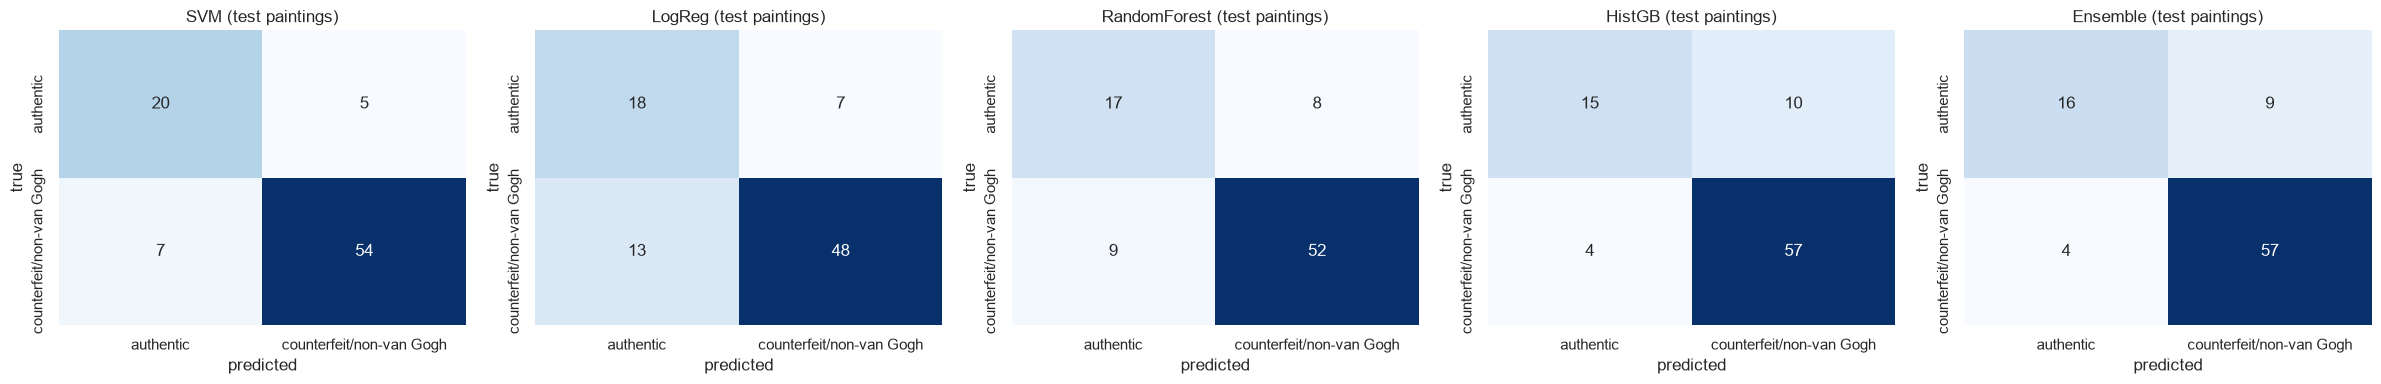

In [24]:
def decision_score(model, X):
    """Higher = more likely POS_LABEL (needed for ROC-AUC)."""
    s = model.decision_function(X) if hasattr(model, "decision_function") else model.predict_proba(X)[:, 1]
    return s if model.classes_[1] == POS_LABEL else -s

def metrics(model, X, y):
    pred = model.predict(X)
    p, r, f, _ = precision_recall_fscore_support(y, pred, average="binary", pos_label=POS_LABEL, zero_division=0)
    return dict(accuracy=accuracy_score(y, pred), precision=p, recall=r, f1=f,
                f1_macro=f1_score(y, pred, average="macro", zero_division=0),
                roc_auc=roc_auc_score(y == POS_LABEL, decision_score(model, X)))

final = {name: s.best_estimator_ for name, s in searches.items()}
summary = pd.DataFrame({**{n: metrics(m, X_te, y_te) for n, m in final.items()},
                        "Baseline (majority)": metrics(baseline, X_te, y_te)}).T
display(summary.round(3))

fig, axes = plt.subplots(1, len(final), figsize=(4.8 * len(final), 4))
for ax, (name, m) in zip(np.atleast_1d(axes), final.items()):
    cm = confusion_matrix(y_te, m.predict(X_te), labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=[LABEL_NAMES[0], LABEL_NAMES[1]], yticklabels=[LABEL_NAMES[0], LABEL_NAMES[1]])
    ax.set_title(f"{name} (test paintings)"); ax.set_xlabel("predicted"); ax.set_ylabel("true")
plt.tight_layout(); plt.show()

In [25]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict

oof_cv = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(X_tr, strat_tr))   # one partition: every painting scored once

def threshold_report(name, model):
    method = "decision_function" if hasattr(model, "decision_function") else "predict_proba"
    oof = cross_val_predict(clone(model), X_tr, y_tr, cv=oof_cv, method=method)
    oof = oof[:, 1] if oof.ndim == 2 else oof                       # score for class 1 (counterfeit); higher = more counterfeit
    default_thr = 0.0 if method == "decision_function" else 0.5

    candidates = np.unique(np.quantile(oof, np.linspace(0.05, 0.95, 91)))
    f1s = [f1_score(y_tr, (oof >= t).astype(int), average="macro") for t in candidates]
    best_thr = candidates[int(np.argmax(f1s))]

    test_scores = decision_score(model, X_te)
    rows = {}
    for label, thr in (("default", default_thr), ("tuned", best_thr)):
        pred = (test_scores >= thr).astype(int)
        rows[label] = dict(threshold=round(float(thr), 3),
                           accuracy=accuracy_score(y_te, pred),
                           f1_macro=f1_score(y_te, pred, average="macro"),
                           authentic_recall=((pred == 0) & (y_te == 0)).sum() / (y_te == 0).sum(),
                           counterfeit_recall=((pred == 1) & (y_te == 1)).sum() / (y_te == 1).sum(),
                           counterfeit_passed_as_authentic=int(((pred == 0) & (y_te == 1)).sum()))
    out = pd.DataFrame(rows).T
    out.insert(0, "model", name)
    return out

display(pd.concat([threshold_report(n, final[n]) for n in ("SVM", "RandomForest", "Ensemble")]).round(3))

,model,threshold,accuracy,f1_macro,authentic_recall,counterfeit_recall,counterfeit_passed_as_authentic
default,SVM,0.000,0.860,0.835,0.80,0.885,7.0
tuned,SVM,-0.136,0.849,0.815,0.72,0.902,6.0
default,RandomForest,0.500,0.802,0.763,0.68,0.852,9.0
tuned,RandomForest,0.589,0.767,0.735,0.72,0.787,13.0
default,Ensemble,0.500,0.849,0.804,0.64,0.934,4.0
tuned,Ensemble,0.461,0.860,0.817,0.64,0.951,3.0


In [26]:
from sklearn.model_selection import cross_validate

X_all, y_all = df_all[FEATURE_COLS].values, df_all["label"].values
strat_all = df_all["subtype"] if df_all["subtype"].value_counts().min() >= 5 else df_all["label"]
all_cv = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=4, random_state=SEED).split(X_all, strat_all))

rows = []
for name, m in list(final.items()) + [("Baseline (majority)", baseline)]:
    t0 = time.time()
    cvres = cross_validate(clone(m), X_all, y_all, cv=all_cv, scoring={"f1_macro": "f1_macro", "accuracy": "accuracy"}, n_jobs=N_JOBS)
    rows.append(dict(model=name, f1_macro=cvres["test_f1_macro"].mean(), f1_std=cvres["test_f1_macro"].std(),
                     accuracy=cvres["test_accuracy"].mean(), seconds=round(time.time() - t0)))
display(pd.DataFrame(rows).round(3))

,model,f1_macro,f1_std,accuracy,seconds
0,SVM,0.794,0.052,0.823,2
1,LogReg,0.756,0.039,0.787,2
2,RandomForest,0.764,0.065,0.801,17
3,HistGB,0.774,0.038,0.816,205
4,Ensemble,0.797,0.050,0.837,218
5,Baseline (majority),0.416,0.002,0.712,0


In [27]:
# Where do the models fail? Accuracy per sub-type, and the misclassified paintings themselves.
for name, m in final.items():
    d = df_te[["painting_id", "subtype", "label", "path"]].copy()
    d["pred"] = m.predict(X_te)
    d["correct"] = d["pred"] == d["label"]
    print(f"--- {name}: accuracy per sub-type ---")
    display(d.groupby("subtype")["correct"].agg(accuracy="mean", n="count").round(3))
    print(f"{name}: misclassified test paintings")
    display(d[~d["correct"]].drop(columns="correct"))

print(classification_report(y_te, final["SVM"].predict(X_te), target_names=[LABEL_NAMES[0], LABEL_NAMES[1]], zero_division=0))

--- SVM: accuracy per sub-type ---


,accuracy,n
subtype,,
other_artist,0.927,41
stable_diffusion,0.833,6
stylegan3_finetuned,1.000,6
stylegan3_random,0.833,6
van_gogh,0.800,25
wacker_forgery,0.000,2


SVM: misclassified test paintings


,painting_id,subtype,label,path,pred
0,P0002,wacker_forgery,1,Vincent Forgeries Wacker\1969141.jpg,0
1,P0006,wacker_forgery,1,Vincent Forgeries Wacker\F614.jpg,0
3,P0014,stable_diffusion,1,Vincent Stable Diffusion\download-14.jpg,0
16,P0084,stylegan3_random,1,Vincent GAN random\seed0015.png,0
21,P0106,van_gogh,0,vgdb_2016\train\vg\vg_24041019.png,1
28,P0131,van_gogh,0,vgdb_2016\train\vg\vg_9362687.png,1
32,P0149,van_gogh,0,vgdb_2016\train\vg\vg_9402635.png,1
34,P0157,van_gogh,0,vgdb_2016\train\vg\vg_9413935.png,1
42,P0212,other_artist,1,vgdb_2016\train\nvg\nvg_16127743.png,0
60,P0301,other_artist,1,vgdb_2016\train\nvg\nvg_24601995.png,0


--- LogReg: accuracy per sub-type ---


,accuracy,n
subtype,,
other_artist,0.756,41
stable_diffusion,0.833,6
stylegan3_finetuned,0.833,6
stylegan3_random,1.000,6
van_gogh,0.720,25
wacker_forgery,0.500,2


... (11 outputs left out)

,accuracy,n
subtype,,
other_artist,0.976,41
stable_diffusion,1.000,6
stylegan3_finetuned,0.833,6
stylegan3_random,0.833,6
van_gogh,0.640,25
wacker_forgery,0.500,2


Ensemble: misclassified test paintings


,painting_id,subtype,label,path,pred
0,P0002,wacker_forgery,1,Vincent Forgeries Wacker\1969141.jpg,0
12,P0058,stylegan3_finetuned,1,Vincent GAN finetune\seed0128.png,0
16,P0084,stylegan3_random,1,Vincent GAN random\seed0015.png,0
21,P0106,van_gogh,0,vgdb_2016\train\vg\vg_24041019.png,1
25,P0119,van_gogh,0,vgdb_2016\train\vg\vg_7058518.png,1
26,P0120,van_gogh,0,vgdb_2016\train\vg\vg_7276652.png,1
28,P0131,van_gogh,0,vgdb_2016\train\vg\vg_9362687.png,1
31,P0146,van_gogh,0,vgdb_2016\train\vg\vg_9395004.png,1
32,P0149,van_gogh,0,vgdb_2016\train\vg\vg_9402635.png,1
34,P0157,van_gogh,0,vgdb_2016\train\vg\vg_9413935.png,1


                          precision    recall  f1-score   support

               authentic       0.74      0.80      0.77        25
counterfeit/non-van Gogh       0.92      0.89      0.90        61

                accuracy                           0.86        86
               macro avg       0.83      0.84      0.83        86
            weighted avg       0.86      0.86      0.86        86



## 11. Comparative analysis

In [28]:
abl_splits = list(RepeatedStratifiedKFold(n_splits=CV_FOLDS, n_repeats=2, random_state=SEED + 1).split(X_tr, strat_tr))
col_idx = {c: i for i, c in enumerate(FEATURE_COLS)}

def run_experiment(label, model_name, cols):
    idx = [col_idx[c] for c in cols]
    est = clone(final[model_name])
    cv_scores = cross_val_score(clone(est), X_tr[:, idx], y_tr, cv=abl_splits, scoring="f1_macro", n_jobs=N_JOBS)
    est.fit(X_tr[:, idx], y_tr)
    pred = est.predict(X_te[:, idx])
    return dict(experiment=label, model=model_name, n_features=len(cols),
                cv_f1_macro=cv_scores.mean(), cv_std=cv_scores.std(),
                test_f1_macro=f1_score(y_te, pred, average="macro"), test_accuracy=accuracy_score(y_te, pred))

rows = []
for model_name in ABLATION_MODELS:
    rows.append(run_experiment("all features", model_name, FEATURE_COLS))
    for g, cols in GROUPS.items():
        rows.append(run_experiment(f"only {g}", model_name, cols))
        rest = [c for c in FEATURE_COLS if c not in cols]
        if rest:
            rows.append(run_experiment(f"without {g}", model_name, rest))
    for s, cols in SCOPES.items():
        rows.append(run_experiment(f"scope: {s}", model_name, cols))

results = pd.DataFrame(rows)
results.to_csv(OUT_DIR / "ablation_results.csv", index=False)
display(results.round(3))

,experiment,model,n_features,cv_f1_macro,cv_std,test_f1_macro,test_accuracy
0,all features,SVM,137,0.782,0.051,0.835,0.860
1,only color,SVM,13,0.681,0.046,0.676,0.721
2,without color,SVM,124,0.761,0.040,0.784,0.814
3,only edge_morph,SVM,26,0.560,0.055,0.682,0.721
4,without edge_morph,SVM,111,0.768,0.033,0.795,0.826
5,only glcm,SVM,36,0.572,0.047,0.622,0.651
6,without glcm,SVM,101,0.784,0.054,0.819,0.849
7,only intensity,SVM,6,0.653,0.058,0.670,0.686
8,without intensity,SVM,131,0.765,0.055,0.835,0.860
9,only lbp,SVM,56,0.670,0.038,0.735,0.767


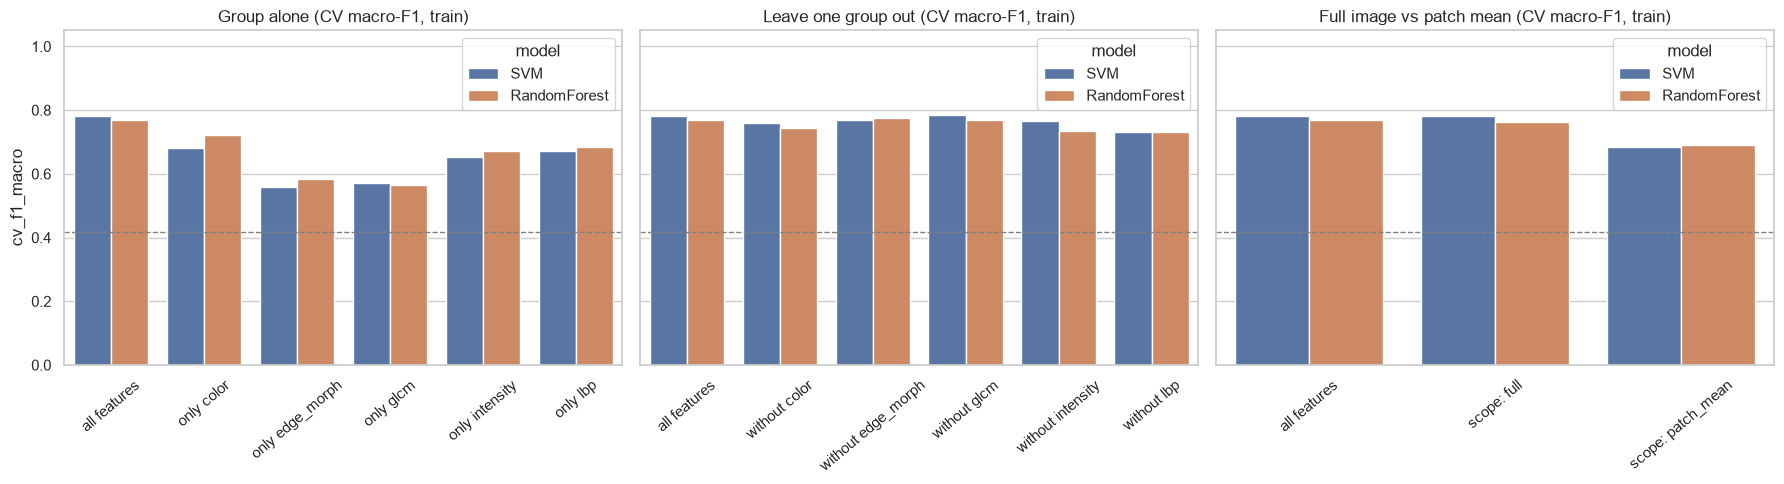

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for ax, (pat, title) in zip(axes, [("only|all", "Group alone"), ("without|all", "Leave one group out"), ("scope|all", "Full image vs patch mean")]):
    sns.barplot(data=results[results["experiment"].str.contains(pat)], x="experiment", y="cv_f1_macro", hue="model", ax=ax)
    ax.axhline(base_cv, color="grey", ls="--", lw=1, label="majority baseline")
    ax.set_title(f"{title} (CV macro-F1, train)"); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=40); ax.set_ylim(0, 1.05)
plt.tight_layout(); plt.show()

In [30]:
AUTH_SUBTYPE = "van_gogh"
VGDB_SUBTYPES = ["van_gogh", "other_artist"]
FORGERY_SUBTYPES = [s for s in df_all["subtype"].unique() if s not in VGDB_SUBTYPES]
TASKS = {"all paintings": None,
         "VGDB only (van Gogh vs other artists)": VGDB_SUBTYPES,
         "van Gogh vs forgeries/AI": [AUTH_SUBTYPE] + FORGERY_SUBTYPES}

rows = []
for task, subtypes in TASKS.items():
    mtr = np.ones(len(df_tr), bool) if subtypes is None else df_tr["subtype"].isin(subtypes).values
    mte = np.ones(len(df_te), bool) if subtypes is None else df_te["subtype"].isin(subtypes).values
    if len(np.unique(y_tr[mtr])) < 2 or len(np.unique(y_te[mte])) < 2:
        print("skipped (one class missing):", task); continue
    task_cv = list(RepeatedStratifiedKFold(n_splits=CV_FOLDS, n_repeats=2, random_state=SEED).split(X_tr[mtr], y_tr[mtr]))
    for model_name in ABLATION_MODELS:
        est = clone(final[model_name])
        cv_f1 = cross_val_score(clone(est), X_tr[mtr], y_tr[mtr], cv=task_cv, scoring="f1_macro", n_jobs=N_JOBS)
        est.fit(X_tr[mtr], y_tr[mtr])
        pred = est.predict(X_te[mte])
        rows.append(dict(task=task, model=model_name, n_train=int(mtr.sum()), n_test=int(mte.sum()),
                         cv_f1_macro=cv_f1.mean(), cv_std=cv_f1.std(),
                         test_f1_macro=f1_score(y_te[mte], pred, average="macro"),
                         test_accuracy=accuracy_score(y_te[mte], pred)))
task_results = pd.DataFrame(rows)
task_results.to_csv(OUT_DIR / "task_variants.csv", index=False)
display(task_results.round(3))

,task,model,n_train,n_test,cv_f1_macro,cv_std,test_f1_macro,test_accuracy
0,all paintings,SVM,344,86,0.785,0.044,0.835,0.860
1,all paintings,RandomForest,344,86,0.755,0.062,0.763,0.802
2,VGDB only (van Gogh vs other artists),SVM,265,66,0.823,0.055,0.902,0.909
3,VGDB only (van Gogh vs other artists),RandomForest,265,66,0.805,0.061,0.825,0.848
4,van Gogh vs forgeries/AI,SVM,178,45,0.845,0.084,0.863,0.867
5,van Gogh vs forgeries/AI,RandomForest,178,45,0.803,0.076,0.821,0.822


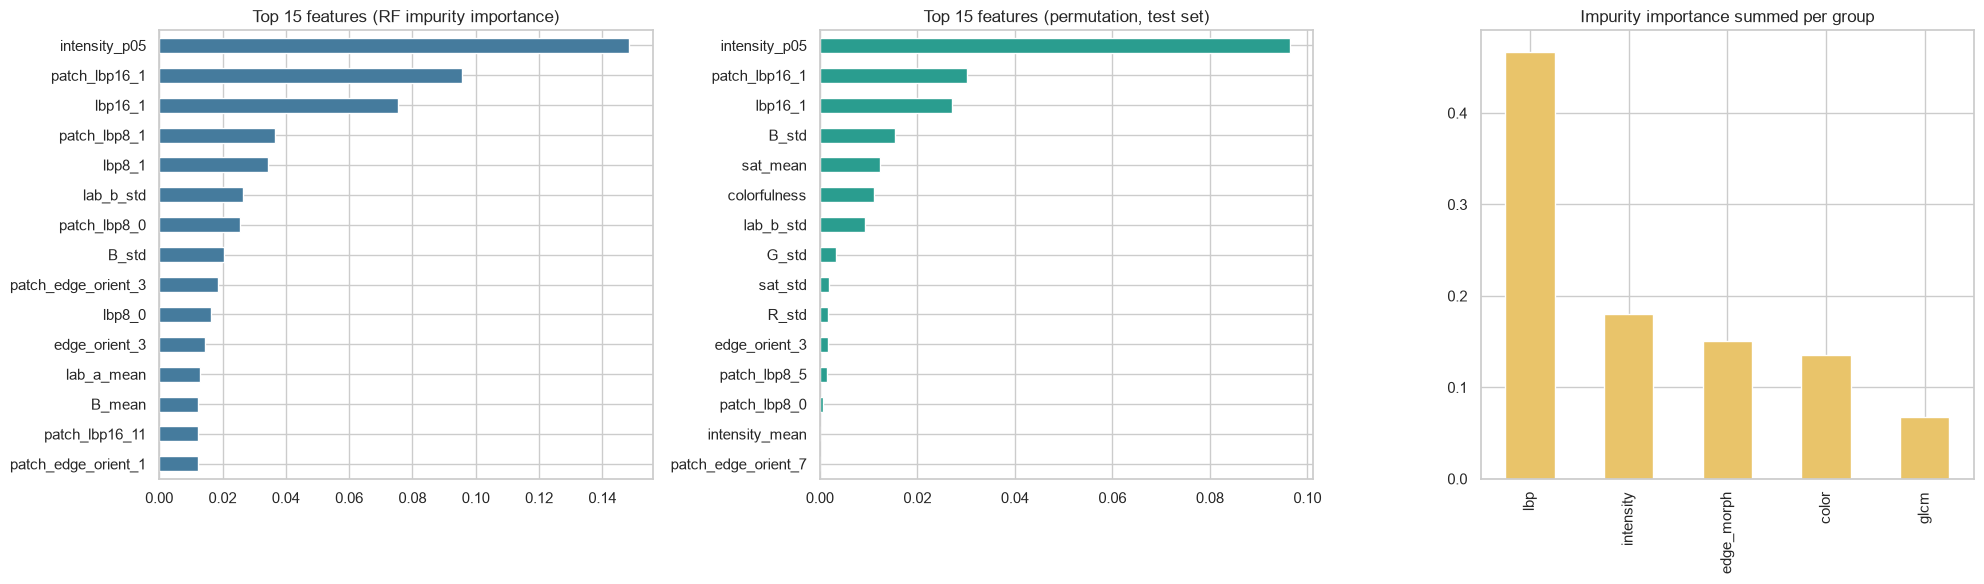

In [31]:
# Which features matter? Random Forest impurity importance and permutation importance on the test set
rf_best = final["RandomForest"]
imp = pd.Series(rf_best.named_steps["clf"].feature_importances_, index=FEATURE_COLS).sort_values(ascending=False)
perm = permutation_importance(rf_best, X_te, y_te, scoring="f1_macro", n_repeats=20, random_state=SEED, n_jobs=N_JOBS)
perm_imp = pd.Series(perm.importances_mean, index=FEATURE_COLS).sort_values(ascending=False)

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
imp.head(15)[::-1].plot.barh(ax=axes[0], color="#457b9d"); axes[0].set_title("Top 15 features (RF impurity importance)")
perm_imp.head(15)[::-1].plot.barh(ax=axes[1], color="#2a9d8f"); axes[1].set_title("Top 15 features (permutation, test set)")
pd.Series({g: imp[c].sum() for g, c in GROUPS.items()}).sort_values(ascending=False).plot.bar(ax=axes[2], color="#e9c46a")
axes[2].set_title("Impurity importance summed per group")
plt.tight_layout(); plt.show()